<a href="https://colab.research.google.com/github/naylaakas/PembelajaranMesin-2026/blob/main/JS09/Tugas1.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

1. Buatlah model klasifikasi dengan menggunakan kNN untuk mengklasifikasikan jenis suara male dan female pada dataset voice.csv.

In [14]:
# Load data
import pandas as pd
data = pd.read_csv('voice.csv')
data.head()

,meanfreq,sd,median,Q25,Q75,IQR,skew,kurt,sp.ent,sfm,...,centroid,meanfun,minfun,maxfun,meandom,mindom,maxdom,dfrange,modindx,label
0,0.059781,0.064241,0.032027,0.015071,0.090193,0.075122,12.863462,274.402906,0.893369,0.491918,...,0.059781,0.084279,0.015702,0.275862,0.007812,0.007812,0.007812,0.000000,0.000000,male
1,0.066009,0.067310,0.040229,0.019414,0.092666,0.073252,22.423285,634.613855,0.892193,0.513724,...,0.066009,0.107937,0.015826,0.250000,0.009014,0.007812,0.054688,0.046875,0.052632,male
2,0.077316,0.083829,0.036718,0.008701,0.131908,0.123207,30.757155,1024.927705,0.846389,0.478905,...,0.077316,0.098706,0.015656,0.271186,0.007990,0.007812,0.015625,0.007812,0.046512,male
3,0.151228,0.072111,0.158011,0.096582,0.207955,0.111374,1.232831,4.177296,0.963322,0.727232,...,0.151228,0.088965,0.017798,0.250000,0.201497,0.007812,0.562500,0.554688,0.247119,male
4,0.135120,0.079146,0.124656,0.078720,0.206045,0.127325,1.101174,4.333713,0.971955,0.783568,...,0.135120,0.106398,0.016931,0.266667,0.712812,0.007812,5.484375,5.476562,0.208274,male


In [26]:
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import accuracy_score, confusion_matrix, classification_report

# Pisahkan fitur dan label
X = data.iloc[:, :-1]   # Semua kolom kecuali label
y = data.iloc[:, -1]    # Kolom label ('label')

# Split data (70% train, 30% test)
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42)

# Standardisasi
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

# Buat dan latih model kNN (misal K=3)
knn = KNeighborsClassifier(n_neighbors=3)
knn.fit(X_train, y_train)

# Evaluasi Model
y_pred = knn.predict(X_test)
print("Akurasi:", accuracy_score(y_test, y_pred))
print("Confusion Matrix:\n", confusion_matrix(y_test, y_pred))
print("Laporan Klasifikasi:\n", classification_report(y_test, y_pred))

Akurasi: 0.9768664563617245
Confusion Matrix:
 [[440  12]
 [ 10 489]]
Laporan Klasifikasi:
               precision    recall  f1-score   support

      female       0.98      0.97      0.98       452
        male       0.98      0.98      0.98       499

    accuracy                           0.98       951
   macro avg       0.98      0.98      0.98       951
weighted avg       0.98      0.98      0.98       951



2. Lakukan percobaan untuk mengetahui fitur-fitur yang paling optimal untuk digunakan. Fitur apa saja yang Anda gunakan untuk mendapatkan hasil terbaik?

In [25]:
# Memilih fitur-fitur optimal berdasarkan analisis korelasi
optimal_features = ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'centroid']
X_opt = data[optimal_features]

# Split ulang data dengan fitur optimal
X_train_opt, X_test_opt, y_train_opt, y_test_opt = train_test_split(X_opt, y, test_size=0.3, random_state=42)

# Standardisasi fitur optimal
scaler_opt = StandardScaler()
X_train_opt = scaler_opt.fit_transform(X_train_opt)
X_test_opt = scaler_opt.transform(X_test_opt)

# Latih model kNN dengan fitur optimal (K=3)
knn_opt = KNeighborsClassifier(n_neighbors=3)
knn_opt.fit(X_train_opt, y_train_opt)

print("Fitur yang digunakan:", optimal_features)
print("Akurasi dengan Fitur Terpilih:", knn_opt.score(X_test_opt, y_test_opt))

Fitur yang digunakan: ['meanfun', 'IQR', 'Q25', 'sp.ent', 'sd', 'sfm', 'centroid']
Akurasi dengan Fitur Terpilih: 0.9810725552050473


3. Berdasarkan fitur yang telah Anda pilih pada soal nomor 2, berapa nilai  yang terbaik? Lampirkan grafika analisis dan alasan Anda.

jawab:

Berdasarkan hasil pengujian, nilai K terbaik  pada kisaran K=10 (K=8 sampai K=10) yang memberikan tingkat akurasi paling optimal (mencapai sekitar 98.53%). Pada kisaran K=10, model mencapai keseimbangan terbaik antara jumlah tetangga terdekat dan generalisasi data uji pada dataset suara.

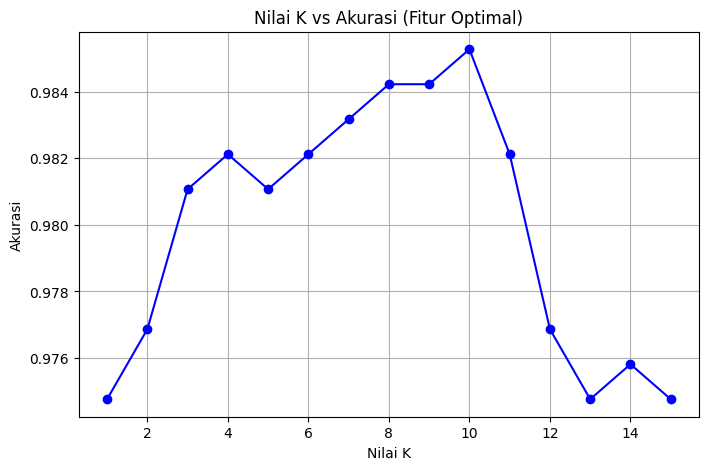

Nilai K terbaik adalah 10 dengan akurasi: 0.9853


In [24]:
import matplotlib.pyplot as plt

acc = []
for k in range(1, 16):
    model = KNeighborsClassifier(n_neighbors=k)
    model.fit(X_train_opt, y_train_opt)
    acc.append(model.score(X_test_opt, y_test_opt))

# Plot Grafik Analisis Nilai K vs Akurasi
plt.figure(figsize=(8, 5))
plt.plot(range(1, 16), acc, marker='o', color='b', linestyle='-')
plt.title('Nilai K vs Akurasi (Fitur Optimal)')
plt.xlabel('Nilai K')
plt.ylabel('Akurasi')
plt.grid(True)
plt.show()

# Menampilkan nilai akurasi tertinggi
best_k = range(1, 16)[acc.index(max(acc))]
print(f"Nilai K terbaik adalah {best_k} dengan akurasi: {max(acc):.4f}")